In [1]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import torch.nn as nn
import numpy as np
import os
import matplotlib
from matplotlib import animation 
from IPython.display import HTML 
import matplotlib.pyplot as plt
import copy
os.environ["MUJOCO_GL"] = "egl"
from dm_control import suite
import glob
from torch.utils.data import DataLoader, Dataset
from models import VAE, vae_loss
device

device(type='cuda')

Data Loading 

In [2]:
def split_files(path, test_frac = 0.2):
    """Takes a directory of recorded eps, returns train/test/split files"""
    # path = 'data/cartpole_swingup_episodes'
    files = sorted(os.listdir(path))
    num_of_files = len(files)
    test_num = int(num_of_files * test_frac)
    test_files = files[:test_num]
    train_files = files[test_num:]
    return train_files, test_files 


def get_frames(files, path):
    "takes list of episode files, loads it, and concatenates the frames"
    episodes = []
    for file in files:
        with np.load(os.path.join(path, file)) as f: # f is a variable 
            episode_frames = f['frames']
            episodes.append(episode_frames)
    frames = np.concatenate(episodes, axis = 0)
    return frames 

In [3]:
train_files, test_files = split_files(path = 'data/cartpole_swingup_episodes', test_frac = 0.2)

In [4]:
train_frames = get_frames(train_files, path='data/cartpole_swingup_episodes')
test_frames = get_frames(test_files, path='data/cartpole_swingup_episodes')

In [5]:
class FramesDataset(Dataset): # inherits from Pytorch's Dataset
    def __init__(self, frames): # methods are functions inside the class
        self.frames = frames 

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, idx):
        "takes an index, returns a frame from episodes"
        frame = self.frames[idx] # 64, 64, 3 
        frame_tensor = torch.from_numpy(frame).float().permute(2, 0, 1)/ 255 # normalized, used to be H, W, C
        return frame_tensor


In [6]:
# create both datasets (train and test)
train_dataset = FramesDataset(train_frames)
test_dataset = FramesDataset(test_frames)

In [7]:
len(train_dataset)

10080

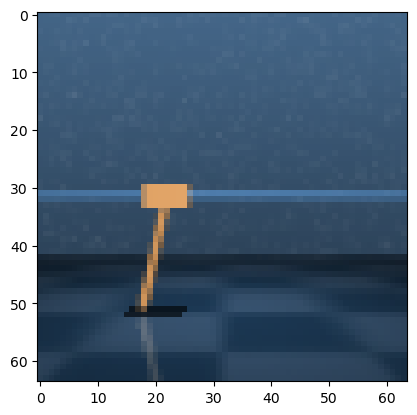

In [8]:
plt.imshow(train_dataset[10].permute(1,2,0))
plt.show()

In [9]:
# make two dataloaders 
train_dataloader = DataLoader(train_dataset, batch_size = 64, shuffle = True)
test_dataloader = DataLoader(test_dataset, batch_size = 64, shuffle = False)

In [29]:
batch1 = next(iter(train_dataloader))

In [30]:
batch1.shape

torch.Size([64, 3, 64, 64])

In [31]:
# (input - kernel) / stride + 1

Sanity checks, rerun after changing VAE model

In [ ]:
#single batch small trial
#fresh model set up!
vae = VAE()
# move model to device
vae.to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr = 0.001)
loss_history = []
# one batch check
batch1 = batch1.to(device) #have to assign tensor to device but you also have to assign it
for step in range(1000):
    recon, z_mu, z_logvar = vae(batch1)
    total_loss, recon_loss, kl_loss = vae_loss(recon, batch1, z_mu, z_logvar, beta = 0.2)
    optimizer.zero_grad() # clear gradients from the previous step
    total_loss.backward()
    optimizer.step()
    batch_dic = {
        'total_loss': total_loss.item(), #stored as items 
        'recon_loss': recon_loss.item(),
        'kl_loss': kl_loss.item()
    }
    loss_history.append(batch_dic) #indent inside
    if step % 20 == 0: 
        print(f'step {step}', total_loss, recon_loss, kl_loss)
    



step 0 tensor(720.0604, device='cuda:0', grad_fn=<AddBackward0>) tensor(720.0604, device='cuda:0', grad_fn=<DivBackward0>) tensor(0.0096, device='cuda:0', grad_fn=<MeanBackward0>)
step 20 tensor(91.0755, device='cuda:0', grad_fn=<AddBackward0>) tensor(91.0755, device='cuda:0', grad_fn=<DivBackward0>) tensor(0.0085, device='cuda:0', grad_fn=<MeanBackward0>)
step 40 tensor(48.1406, device='cuda:0', grad_fn=<AddBackward0>) tensor(48.1406, device='cuda:0', grad_fn=<DivBackward0>) tensor(0.0151, device='cuda:0', grad_fn=<MeanBackward0>)
step 60 tensor(35.5282, device='cuda:0', grad_fn=<AddBackward0>) tensor(35.5282, device='cuda:0', grad_fn=<DivBackward0>) tensor(0.0218, device='cuda:0', grad_fn=<MeanBackward0>)
step 80 tensor(32.1546, device='cuda:0', grad_fn=<AddBackward0>) tensor(32.1546, device='cuda:0', grad_fn=<DivBackward0>) tensor(0.0248, device='cuda:0', grad_fn=<MeanBackward0>)
step 100 tensor(28.8236, device='cuda:0', grad_fn=<AddBackward0>) tensor(28.8236, device='cuda:0', grad_

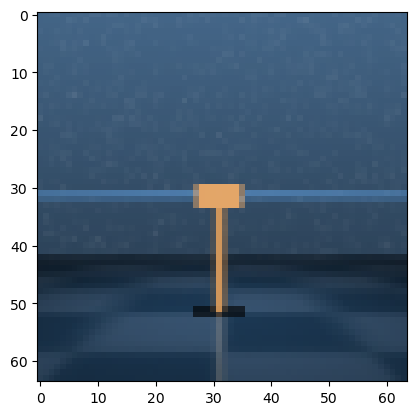

In [78]:
# noticed that KL loss is not changing, but the recon is. 
# the images are all being encoded as an average pole, same z
#verified in imshow that the recons are all different, so the encoder is working,
plt.imshow(train_dataset[0].permute(1,2,0))
plt.show()

In [79]:
recon_arr = recon.detach().cpu() #first detatch it from gradient tracking then move it from gpu to cpu

In [80]:
recon_arr.shape

torch.Size([64, 3, 64, 64])

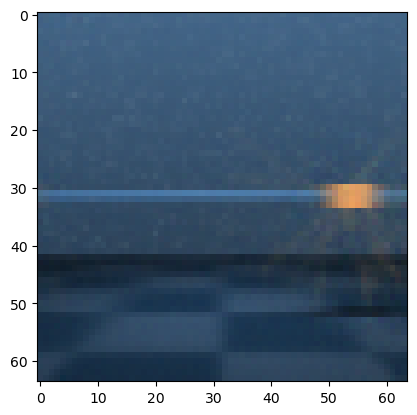

In [81]:
plt.imshow(recon_arr[0].permute(1,2,0))
plt.show()


In [ ]:
# fixes to see the pole again in reconstruction
# 1. try beta = 0, so we can confirm the weights on z can be properly used to encode the full image details
#2. if 1. works, try a lower beta = 0.02 
# 3. can try using free bits ( allowing the KL term in the loss to be zero up to a certain threshold,
#so that the z being further from N(0,1) wont get penalized by the KL term)

Run VAE and check outputs

In [123]:
def run_vae(train_dataloader , test_dataloader, beta = 0.2, epochs = 10, lr = 0.001, zdim = 32, kl_tolerance = None ):
    #fresh model set up!
    vae = VAE(zdim)
    # move model to device
    vae.to(device)
    optimizer = torch.optim.Adam(vae.parameters(), lr )
    loss_history = []

    # epochs = 10
    # beta = 0.2
    for epoch in range(epochs):
        vae.train()
        total_total = 0
        recon_total = 0
        KL_total = 0
        test_total_total = 0
        test_recon_total = 0
        test_KL_total = 0
        for batch in train_dataloader:
            batch = batch.to(device) #have to assign tensor to device but you also have to assign it
            recon, z_mu, z_logvar = vae(batch)
            total_loss, recon_loss, kl_loss = vae_loss(recon, batch, z_mu, z_logvar, beta, kl_tolerance)
            optimizer.zero_grad() # clear gradients from the previous step
            total_loss.backward()
            optimizer.step()
            total_total += total_loss.item()
            recon_total +=recon_loss.item()
            KL_total +=kl_loss.item()
        epoch_total_average = total_total/len(train_dataloader)
        epoch_recon_average = recon_total/len(train_dataloader)
        epoch_KL_average = KL_total/len(train_dataloader)
        #evaluate on test loader
        vae.eval()
        with torch.no_grad():
            for test_batch in test_dataloader:
                #move batch to device
                test_batch = test_batch.to(device)
                #run forward pass
                test_recon, test_z_mu, test_z_logvar = vae(test_batch)
                #compute loss
                test_total_loss, test_recon_loss, test_kl_loss = vae_loss(test_recon, test_batch, test_z_mu, test_z_logvar, beta, kl_tolerance)
                # add item values to test totals
                test_total_total += test_total_loss.item()
                test_recon_total += test_recon_loss.item()
                test_KL_total += test_kl_loss.item()
            average_test_total_loss = test_total_total/len(test_dataloader)
            average_test_total_recon_loss = test_recon_total/len(test_dataloader)
            average_test_total_kl_loss = test_KL_total/len(test_dataloader)

        print(f'epoch {epoch} | train total {epoch_total_average:.1f} recon {epoch_recon_average:.1f} kl {epoch_KL_average:.1f}'
            f' | test total {average_test_total_loss:.1f} recon {average_test_total_recon_loss:.1f} kl {average_test_total_kl_loss:.1f}')
        epoch_loss_dic = {
                'epoch_num': epoch,
                'total_loss': epoch_total_average,
                'recon_loss': epoch_recon_average,
                'kl_loss': epoch_KL_average,
                'test_total_loss': average_test_total_loss,
                'test_recon_loss': average_test_total_recon_loss,
                'test_kl_loss': average_test_total_kl_loss
            }
        loss_history.append(epoch_loss_dic)
    torch.save(vae.state_dict(), f'vae_checkpoints/vae_beta{beta}_zdim{zdim}_epochs{epochs}_kltol_{kl_tolerance}model_weights.pth')
    return vae, loss_history

In [2]:
vae_beta02_freebit_ep60, vae_beta02_freebit_ep60_loss = run_vae(train_dataloader , test_dataloader, beta = 0.2, epochs = 60, lr = 0.001, zdim = 32, kl_tolerance = 16 ) # kl is 0.5 per latent dim, 32 x 0.5, per WM paper

NameError: name 'run_vae' is not defined

In [125]:
#plot loss
def plot_losses(loss_history):
    "grabs everything from "
    
# [ what_to_collect  for  item  in  something ]
    total_losses = [epoch['total_loss'] for epoch in loss_history]
    epoch_num = [epoch['epoch_num'] for epoch in loss_history]
    recon_losses = [epoch['recon_loss'] for epoch in loss_history]
    kl_losses = [epoch['kl_loss'] for epoch in loss_history]
    test_total_losses = [epoch['test_total_loss'] for epoch in loss_history]
    test_recon_losses = [epoch['test_recon_loss'] for epoch in loss_history]
    test_kl_losses = [epoch['test_kl_loss'] for epoch in loss_history]

#plot reconstruction
    fig, axes = plt.subplots(1, 2, figsize = (10,4)) # 1 row, two plots

    axes[0].plot( epoch_num, recon_losses, label = 'training')
    axes[0].plot( epoch_num, test_recon_losses, label = 'test')
    axes[0].set_title('reconstruction loss')
    axes[0].set_xlabel('epochs')
    axes[0].legend()

    axes[1].plot( epoch_num, kl_losses, label = 'training')
    axes[1].plot( epoch_num, test_kl_losses, label = 'test')
    axes[1].set_title('KL loss')
    axes[1].set_xlabel('epochs')
    axes[1].legend()


    plt.show()

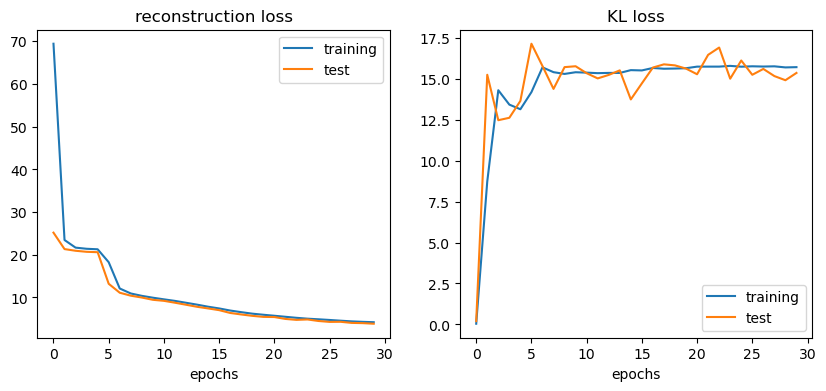

In [136]:
plot_losses(vae_beta0_frbit16__ep30_loss)

In [127]:
def plot_recons(vae, loader, n):
    "n is number of images"
    batch = next(iter(loader))
    vae.eval()
    batch = batch.to(device)
    with torch.no_grad():
        recon, _, _ = vae(batch)
        recon = recon.cpu()
        print(recon.shape)
        batch = batch.cpu()
        print(batch.shape)
   
    fig, axes = plt.subplots(n, 2, figsize = (10,4)) # 1 row, two plots
    for frame in range(n):

        axes[frame, 0].imshow(batch[frame].permute(1,2,0), label = 'training')
        if frame == 0:
            axes[frame, 0].set_title('original')


        axes[frame, 1].imshow( recon[frame].permute(1,2,0), label = 'reconstruction')
        if frame == 0:
            axes[frame, 1].set_title('reconstruction')        
    plt.show()




torch.Size([64, 3, 64, 64])
torch.Size([64, 3, 64, 64])


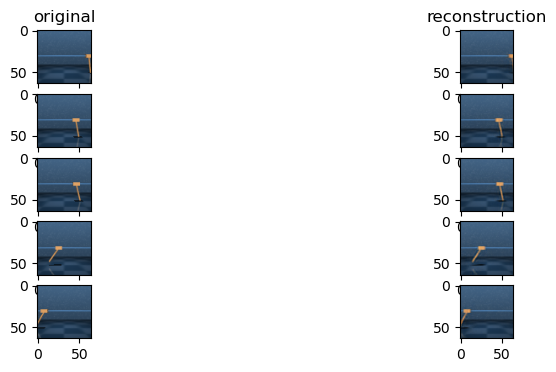

In [144]:

plot_recons(vae_beta02_freebit_ep60, loader= train_dataloader, n= 5)

Encode the episodes once the VAE is trained

In [10]:
# create new model with same architecture as vae model we used
vae_forWM = VAE(z_dim = 32)

In [11]:
# read file that was saved
vae_final_weights = torch.load('vae_checkpoints/vae_beta0.2_zdim32_epochs60_kltol_16model_weights.pth', map_location = device)

/tmp/ipykernel_1974236/3651303071.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  vae_final_weights = torch.load('vae_checkpoints/vae_beta0.2_zdim32_epochs60_kltol_16mod

In [12]:
vae_forWM.load_state_dict(vae_final_weights)

<All keys matched successfully>

In [13]:
vae_forWM.to(device)

VAE(
  (enc_conv1): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2))
  (enc_conv2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
  (enc_conv3): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2))
  (enc_conv4): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2))
  (fc_mu): Linear(in_features=1024, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=1024, out_features=32, bias=True)
  (dec_fc): Linear(in_features=32, out_features=1024, bias=True)
  (dec_conv1): ConvTranspose2d(1024, 128, kernel_size=(5, 5), stride=(2, 2))
  (dec_conv2): ConvTranspose2d(128, 64, kernel_size=(5, 5), stride=(2, 2))
  (dec_conv3): ConvTranspose2d(64, 32, kernel_size=(6, 6), stride=(2, 2))
  (dec_conv4): ConvTranspose2d(32, 3, kernel_size=(6, 6), stride=(2, 2))
)

In [14]:
vae_forWM.eval()

VAE(
  (enc_conv1): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2))
  (enc_conv2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
  (enc_conv3): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2))
  (enc_conv4): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2))
  (fc_mu): Linear(in_features=1024, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=1024, out_features=32, bias=True)
  (dec_fc): Linear(in_features=32, out_features=1024, bias=True)
  (dec_conv1): ConvTranspose2d(1024, 128, kernel_size=(5, 5), stride=(2, 2))
  (dec_conv2): ConvTranspose2d(128, 64, kernel_size=(5, 5), stride=(2, 2))
  (dec_conv3): ConvTranspose2d(64, 32, kernel_size=(6, 6), stride=(2, 2))
  (dec_conv4): ConvTranspose2d(32, 3, kernel_size=(6, 6), stride=(2, 2))
)

In [26]:
os.makedirs('test_encodings_cartpole_swingup')

In [29]:

def encode_episodes(files, path, vae, save_dir_name):
    vae.eval() 
    os.makedirs(save_dir_name, exist_ok=True)
    with torch.no_grad():
        #grab each episode, load frames, actions, and rewards
        for file in files:
            #load the individual file
            file_dict = {}
            with np.load(os.path.join(path, file)) as f: # f is a variable 
                #decode frames, actions, rewards
                episode_frames = f['frames']            
                episode_actions = f['actions']
                episode_rewards = f['rewards']
                #preprocess frames and permute
                episode_frames = torch.from_numpy(episode_frames).float().permute(0, 3, 1, 2)/ 255 # normalized, used to be H, W, C
                #move frames to device
                episode_frames = episode_frames.to(device)
                z_mu, z_logvar = vae.encode(episode_frames)             
                file_dict = {
                    'actions': episode_actions,
                    'rewards': episode_rewards,
                    'z_mu': (z_mu.cpu().numpy()),
                    'z_logvar': (z_logvar.cpu().numpy())
                }
                #save dict
                np.savez_compressed(f'{save_dir_name}/{file}', **file_dict) 

    

In [31]:
encode_episodes(test_files, path='data/cartpole_swingup_episodes', vae=vae_forWM, save_dir_name= 'test_encodings_cartpole_swingup' )